In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.fft
import scipy.interpolate
import scipy.io
import scipy.signal
import seaborn as sns
from matplotlib import pyplot as plt

from config import Config as c

In [4]:
patient_files = sorted(list(c.ECG_ABP_DIR.iterdir()))
patient_files

[PosixPath('data/ecg+abp/p008061_3145453_0020.mat'),
 PosixPath('data/ecg+abp/p009124_3576649_0016.mat'),
 PosixPath('data/ecg+abp/p010842_3523295_0005.mat'),
 PosixPath('data/ecg+abp/p040435_3075521_0044.mat'),
 PosixPath('data/ecg+abp/p040724_3023009_0005.mat'),
 PosixPath('data/ecg+abp/p047874_3602666_0050.mat'),
 PosixPath('data/ecg+abp/p048480_3876369_0016.mat'),
 PosixPath('data/ecg+abp/p054132_3178762_0004.mat'),
 PosixPath('data/ecg+abp/p054586_3860079_0019.mat'),
 PosixPath('data/ecg+abp/p060747_3260530_0003.mat'),
 PosixPath('data/ecg+abp/p061642_3102184_0065.mat'),
 PosixPath('data/ecg+abp/p063402_3496554_0025.mat'),
 PosixPath('data/ecg+abp/p063646_3089087_0007.mat'),
 PosixPath('data/ecg+abp/p064485_3625999_0008.mat'),
 PosixPath('data/ecg+abp/p064916_3181603_0003.mat'),
 PosixPath('data/ecg+abp/p065728_3034248_0015.mat'),
 PosixPath('data/ecg+abp/p066682_3549618_0015.mat'),
 PosixPath('data/ecg+abp/p067763_3295996_0009.mat'),
 PosixPath('data/ecg+abp/p069006_3098482_0012.

In [5]:
patient_file = patient_files[0]
patient_file

PosixPath('data/ecg+abp/p008061_3145453_0020.mat')

In [6]:
patient_data = scipy.io.loadmat(patient_file, squeeze_me=True)

In [7]:
rri = patient_data['rri_data'].astype(int)
t = patient_data['rri_time'].astype(float)

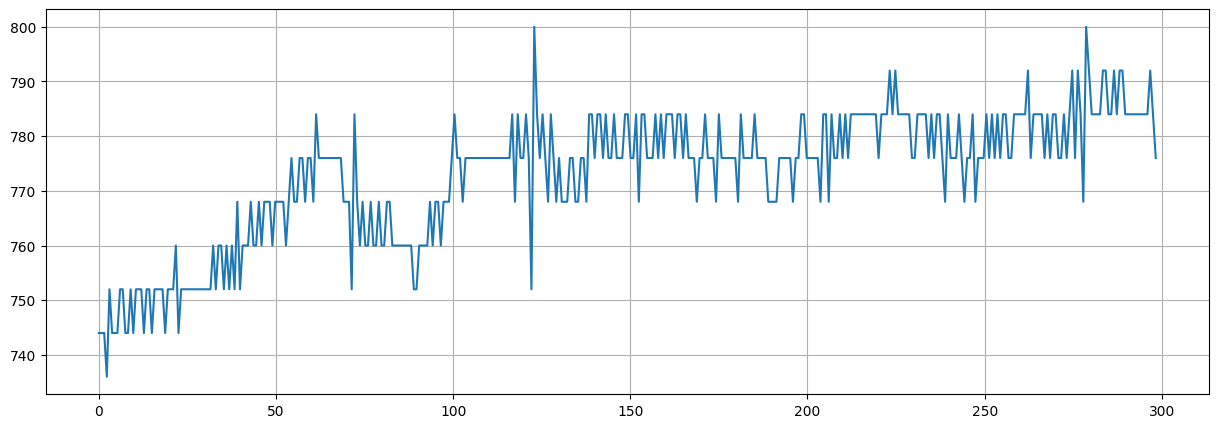

In [8]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(15, 5))
ax.plot(t, rri)
ax.grid()

In [9]:
rri_r = patient_data['rri_resampled_data'].astype(int)
t_r = patient_data['rri_resampled_time'].astype(float)
fs_r = patient_data['rri_resampled_fs']
fs_r

4

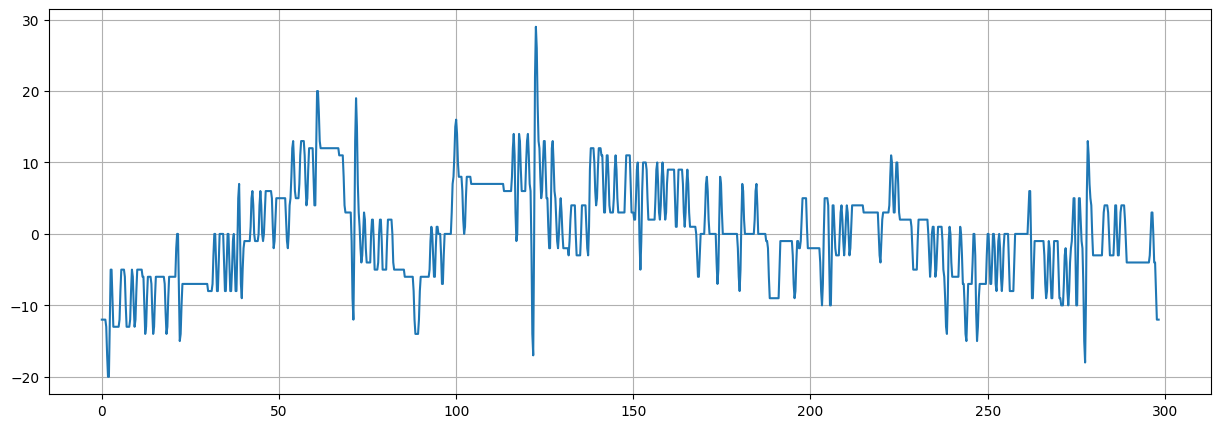

In [10]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(15, 5))
ax.plot(t_r, rri_r)
ax.grid()

In [11]:
ns_s = int(np.ceil((fs_r * t.max())).astype(int))
ns_s

1194

In [12]:
rri_d = scipy.signal.detrend(rri, type='linear')

In [13]:
rri_s, t_s = scipy.signal.resample(rri_d, ns_s, t)

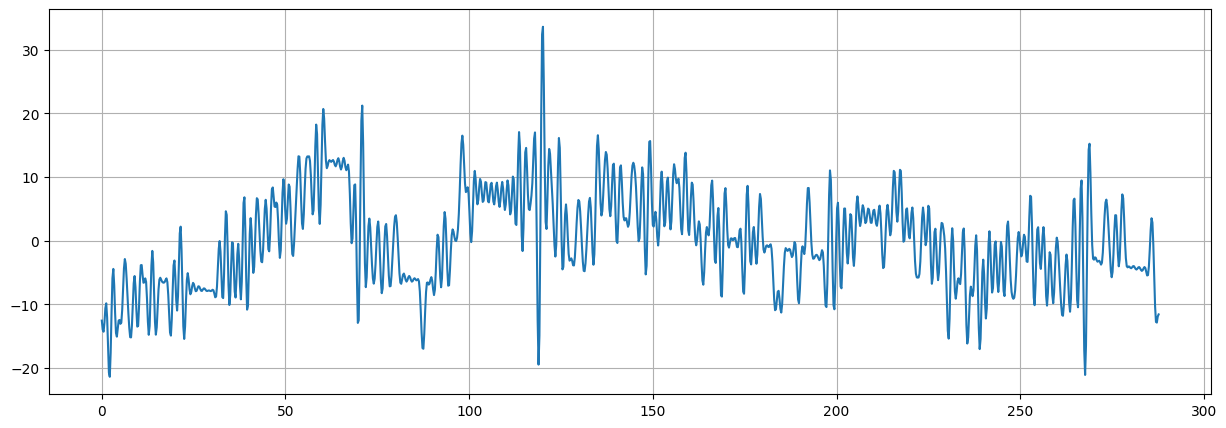

In [14]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(15, 5))
ax.plot(t_s, rri_s)
ax.grid()

In [15]:
freqs_fft = scipy.fft.rfftfreq(n=ns_s, d=1/fs_r)
spectrum = scipy.fft.rfft(x=rri_r, n=ns_s) #  norm='ortho'
mags_fft = 2 * np.abs(spectrum) / ns_s

In [16]:
freqs_welch, pgram = scipy.signal.welch(x=rri_r, fs=fs_r, nperseg=256, noverlap=128)
mags_welch = pgram

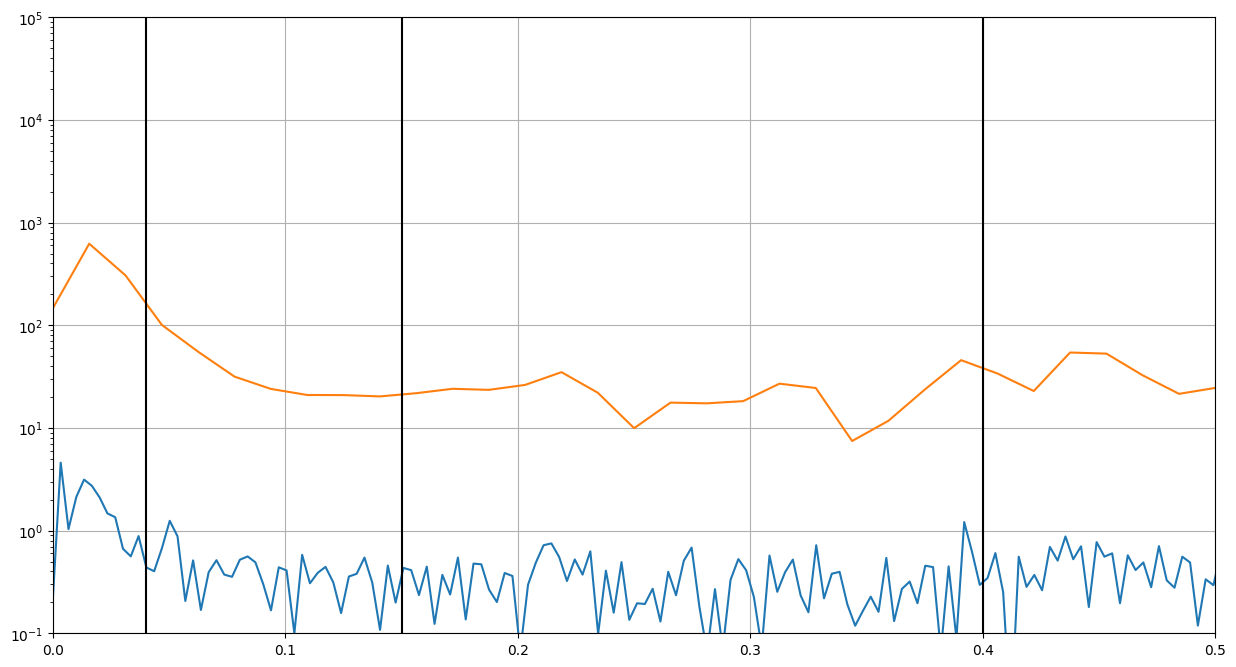

In [17]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(15, 8))
ax.semilogy(freqs_fft, mags_fft, color='C0')
ax.semilogy(freqs_welch, mags_welch, color='C1')
ax.vlines([0.04, 0.15, 0.4], 0.1, 100000, color='black')
ax.set_xlim([0, 0.5])
ax.set_ylim([0.1, 100000])
ax.grid()

In [18]:
mask_vlf = freqs_fft < 0.04
mask_lf = (freqs_fft >= 0.04) & (freqs_fft < 0.15)
mask_hf = (freqs_fft >= 0.15) & (freqs_fft < 0.4)

In [19]:
a_vlf = float(np.trapezoid(mags_fft[mask_vlf], freqs_fft[mask_vlf]))
a_lf = float(np.trapezoid(mags_fft[mask_lf], freqs_fft[mask_lf]))
a_hf = float(np.trapezoid(mags_fft[mask_hf], freqs_fft[mask_hf]))
display((a_vlf, a_lf, a_hf))
display(a_vlf + a_lf + a_hf)
display((a_vlf / (a_vlf + a_lf + a_hf), a_lf / (a_vlf + a_lf + a_hf), a_hf / (a_vlf + a_lf + a_hf)))

(0.06807645017597343, 0.04483144599270365, 0.08483660890718304)

0.1977445050758601

(0.3442646871520272, 0.22671399124595196, 0.42902132160202094)